# **🐍 Intro to Python: Ch 3**

---
## **APIs & Decorators 🔌**

### **Concepts**
- Calling a REST API with `requests`
- Parsing JSON responses  
- The **decorator pattern**: wrap a function to add behaviour without changing it

### **4.1 Calling the GitHub API**

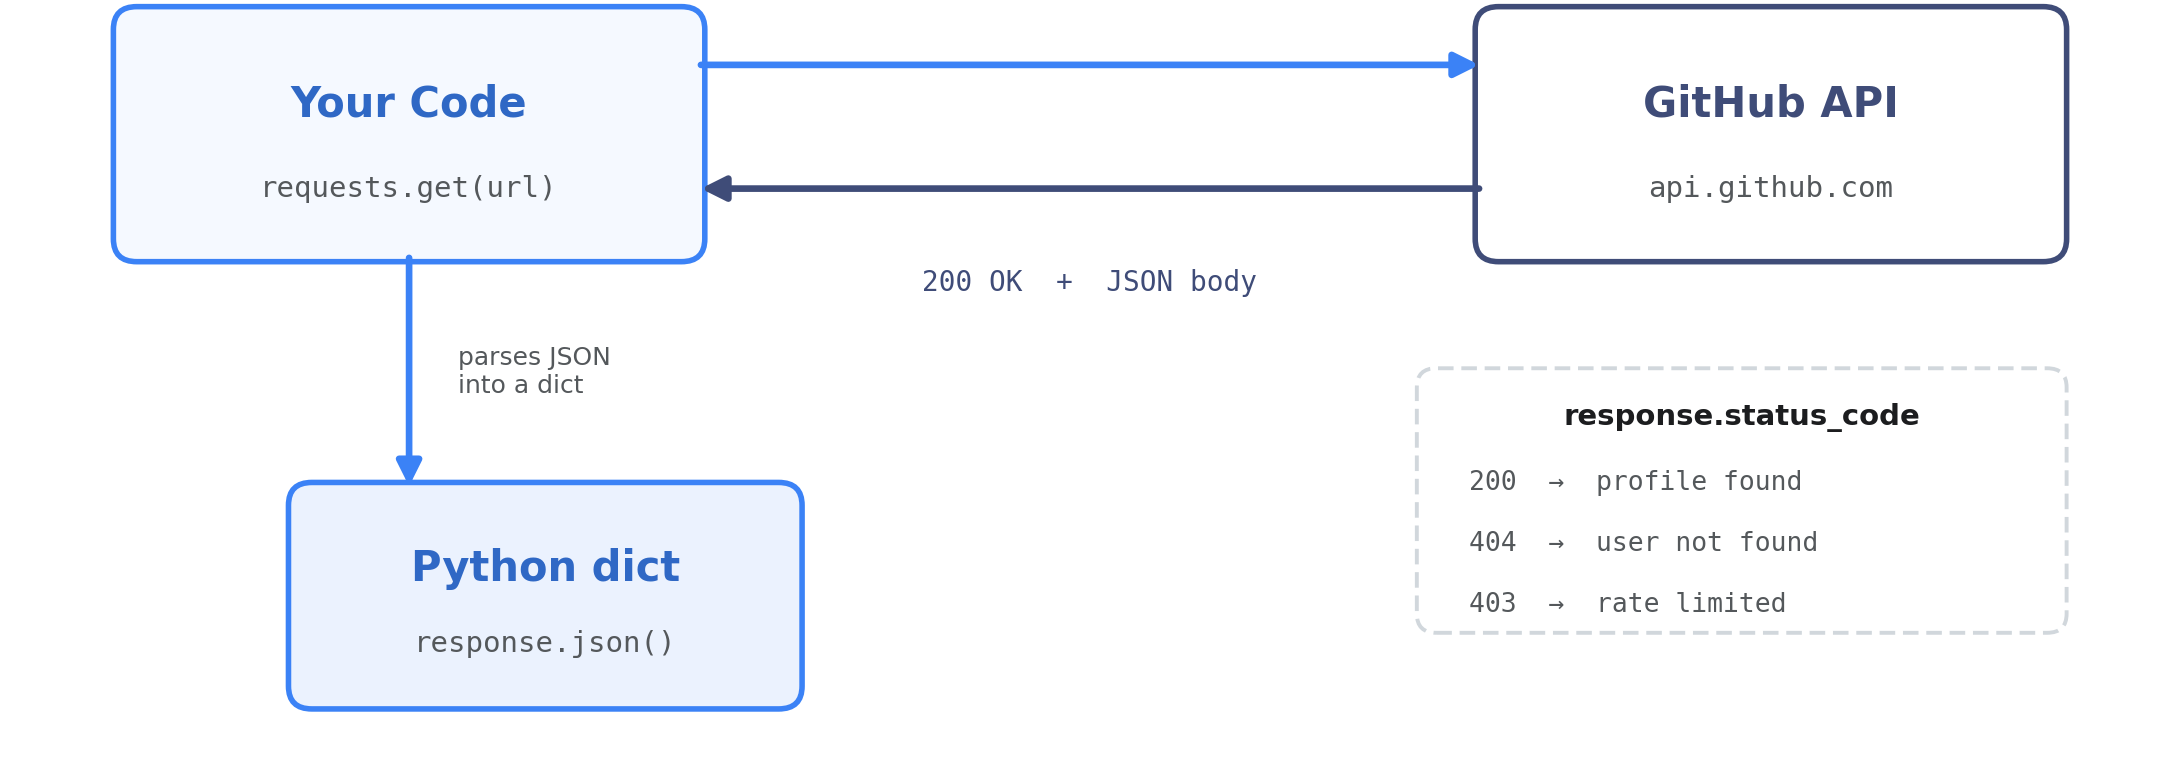

### **Making a Simple Web Request**

In [ ]:
import requests

url = f"https://en.wikipedia.org/wiki/Samosa"
response = requests.get(url)

print(response.text)

Please set a user-agent and respect our robot policy https://w.wiki/4wJS. See also https://phabricator.wikimedia.org/T400119.



In [ ]:
import requests

def analyze_profile(username: str) -> None:
    """Fetch and display a GitHub user's profile."""
    url      = f"https://api.github.com/users/{username}"
    response = requests.get(url)

    if response.status_code != 200:
        print(f"Error: Could not fetch '{username}' (Status: {response.status_code})")
        return

    data = response.json()
    print(f"\n{'=' * 40}")
    print(f"  GitHub Profile: {username}")
    print(f"{'=' * 40}")
    print(f"  Name:      {data.get('name', 'N/A')}")
    print(f"  Bio:       {data.get('bio', 'No bio')}")
    print(f"  Location:  {data.get('location', 'Not specified')}")
    print(f"  Repos:     {data['public_repos']}")
    print(f"  Followers: {data['followers']}")
    print(f"  Following: {data['following']}")
    print(f"  URL:       {data['html_url']}")
    print(f"{'=' * 40}\n")

#Demo
analyze_profile("tnahddisttud")   # Try your GitHub username!


  GitHub Profile: tnahddisttud
  Name:      siddhant.
  Bio:       AI Research @codebasics 👨‍💻 | Physics Enthusiast 🌌
  Location:  127.0.0.1
  Repos:     87
  Followers: 106
  Following: 12
  URL:       https://github.com/tnahddisttud



### **4.2 Without a decorator — manual timing**

In [ ]:
from time import perf_counter

def sum_with_loop(n):
    start = perf_counter()
    total = sum(range(n))
    print(f"sum_with_loop time: {perf_counter() - start:.6f}s")
    return total

def sum_with_formula(n):
    start  = perf_counter()
    result = n * (n - 1) // 2
    print(f"sum_with_formula time: {perf_counter() - start:.6f}s")
    return result

sum_with_loop(5_000)
sum_with_formula(5_000)

sum_with_loop time: 0.000184s
sum_with_formula time: 0.000001s


12497500

### **4.3 With a `@timer` decorator — clean & reusable**

### **4.4 How decorators work under the hood**

```python
@timer
def my_func(): ...

# is exactly equivalent to:
def my_func(): ...
my_func = timer(my_func)
```

The decorator **replaces** `my_func` with `wrapper`, so every call goes through the timing logic.

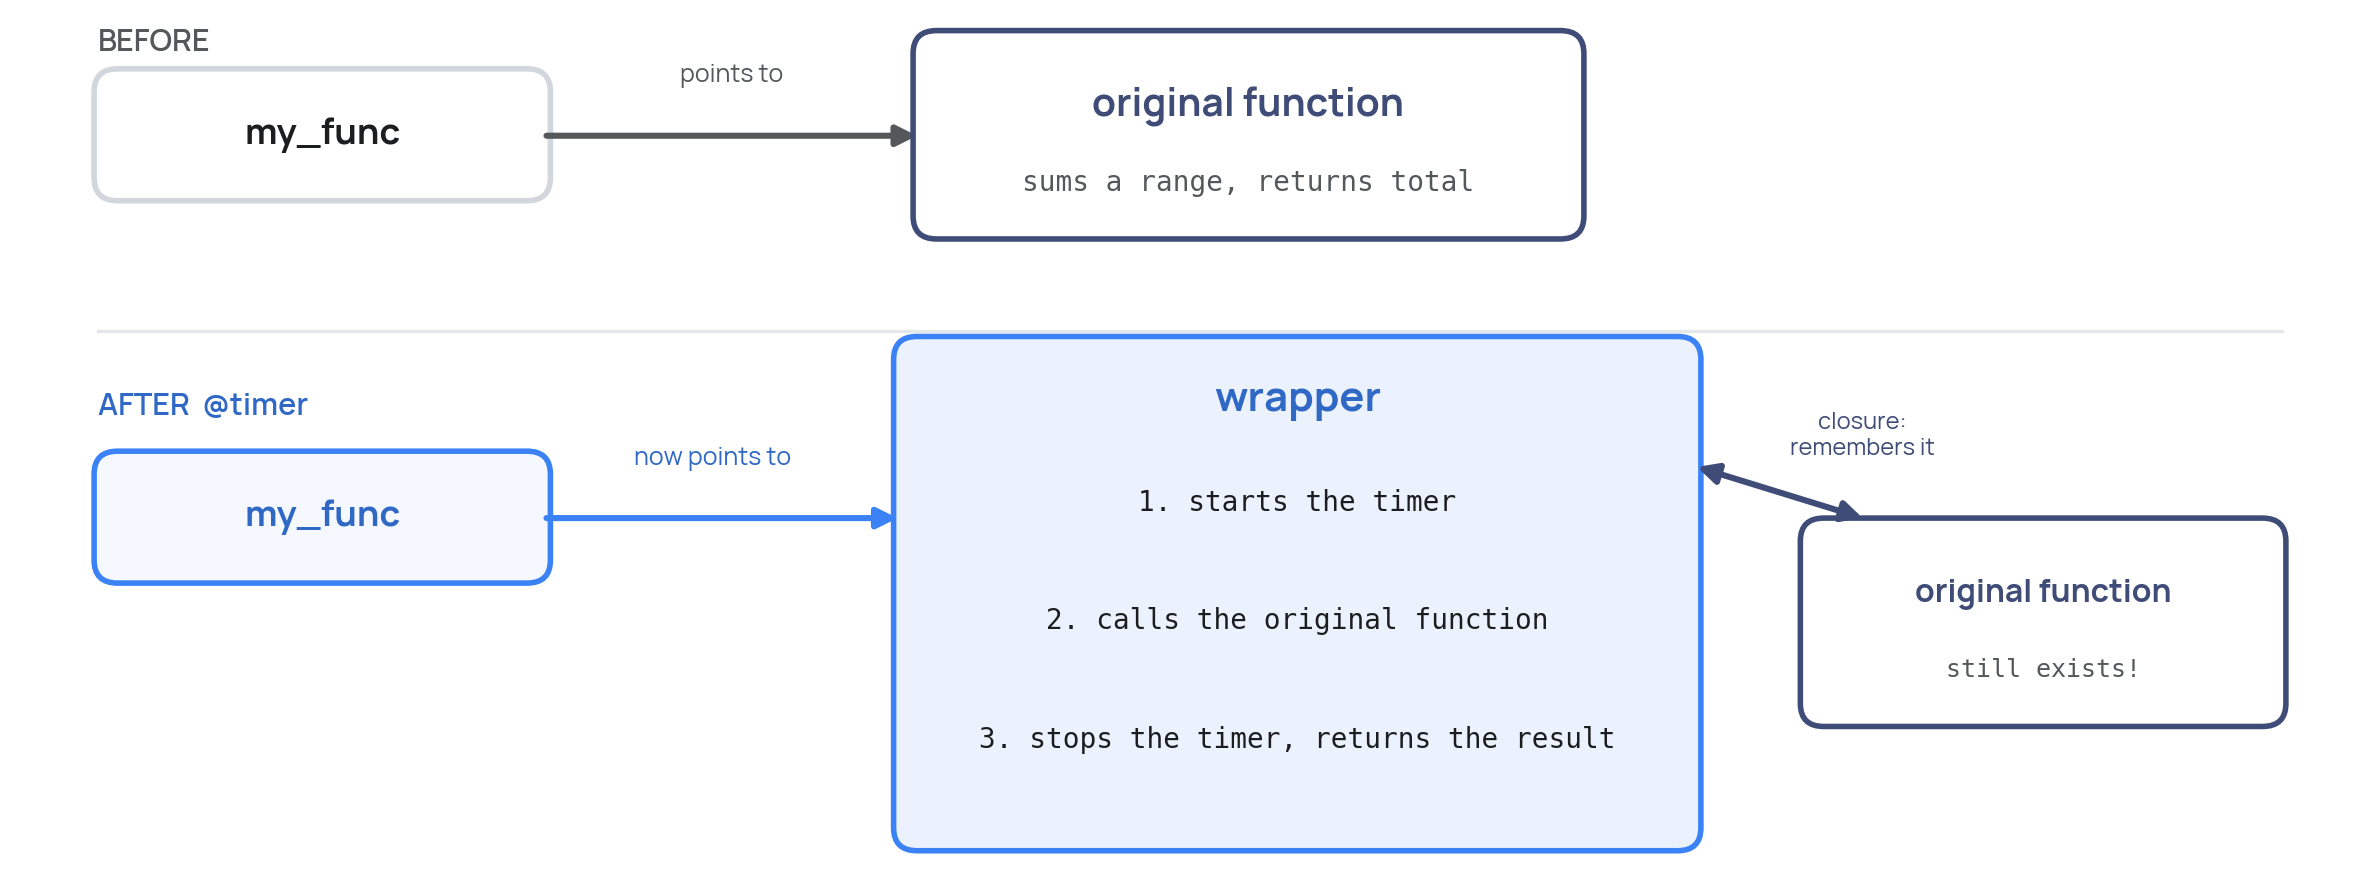

In [ ]:
from time import perf_counter

def timer(func):
    """Decorator that prints execution time of any wrapped function."""
    def wrapper(*args, **kwargs):
        start  = perf_counter()
        result = func(*args, **kwargs)
        print(f"{func.__name__} time: {perf_counter() - start:.6f}s")
        return result
    return wrapper


@timer
def sum_with_loop(n):
    return sum(range(n))

@timer
def sum_with_formula(n):
    return n * (n - 1) // 2


sum_with_loop(5_000)
sum_with_formula(5_000)

sum_with_loop time: 0.000125s
sum_with_formula time: 0.000002s


12497500

### **4.5 ✏️ Exercises**
1. Write a `@retry(n)` decorator that re-calls a function up to `n` times if it raises an exception.
2. Use the GitHub API to fetch a user's **repositories** (`/users/{username}/repos`) and print the top 5 by star count.
3. Combine both: wrap `analyze_profile` with `@timer` to see how long the API call takes.

### 🔑 Getting a Groq API key

You only need to do this once.

1. Go to **[console.groq.com](https://console.groq.com/keys)** and sign up — email, Google, or GitHub all work. No credit card needed.
2. In the left sidebar, click **API Keys** → **Create API Key**.
3. Give it a name (e.g. `my-groq-key`) and click **Create**.
4. **Copy the key immediately** — Groq shows it to you exactly once. If you lose it, you'll have to create a new one.
5. Paste it into your `.env` file (copy `.env.sample` to `.env` first):
   ```
   GROQ_API_KEY=your_key_here
   ```
6. Never commit `.env` to git or paste your key into a shared notebook cell, this project's `.gitignore` already excludes it, keep it that way.

In [ ]:
def sum(**kwargs):
  s = 0
  print(kwargs)
  for k,v in kwargs.items():
    s +=v
  return s

In [ ]:
sum(a=4,b=5,c=7)

{'a': 4, 'b': 5, 'c': 7}


16